# 05 — Company Risk Benchmarking

> **Where should operational reviews begin, with appropriate volume guardrails?**

| | |
|---|---|
| **Audience** | Compliance reviewers, CX leadership |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~20 s on the bundled sample |
| **Reproduces from** | `data/raw/cfpb_sample.csv` |

## Business question

Which companies carry the highest complaint volume and risk burden, and how do we avoid drawing conclusions from low-volume noise?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/05/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/05/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("05")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,05


## 1. Load and aggregate by company

In [2]:
complaints = load_complaints(ctx)
company_summary_full = concentration_table(complaints, "company", top_n=200)
company_summary_full.head(15)

,company,complaints,avg_risk_score,high_risk_share_pct
0,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",285,3.50,12.60
1,"EQUIFAX, INC.",253,3.56,14.20
2,Experian Information Solutions Inc.,230,3.60,14.30
3,"CITIBANK, N.A.",17,2.66,0.00
4,WELLS FARGO & COMPANY,17,2.38,0.00
5,JPMORGAN CHASE & CO.,15,2.00,0.00
6,"BANK OF AMERICA, NATIONAL ASSOCIATION",9,3.56,22.20
7,CAPITAL ONE FINANCIAL CORPORATION,8,2.28,12.50
8,GOLDMAN SACHS BANK USA,7,2.29,0.00
9,Resurgent Capital Services L.P.,6,4.38,16.70


## 2. Apply a minimum-volume filter for stable comparisons

Without this filter, a single complaint at a small company can produce a 100% high-risk share &mdash; visually striking but statistically meaningless.

In [3]:
min_volume = 20
company_filtered = company_summary_full[company_summary_full["complaints"] >= min_volume]
company_filtered = company_filtered.sort_values("high_risk_share_pct", ascending=False)
print(f"Companies kept after filter (>= {min_volume} complaints): {len(company_filtered)}")
company_filtered

Companies kept after filter (>= 20 complaints): 3


,company,complaints,avg_risk_score,high_risk_share_pct
2,Experian Information Solutions Inc.,230,3.60,14.30
1,"EQUIFAX, INC.",253,3.56,14.20
0,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",285,3.50,12.60


## 3. Volume vs. risk side by side

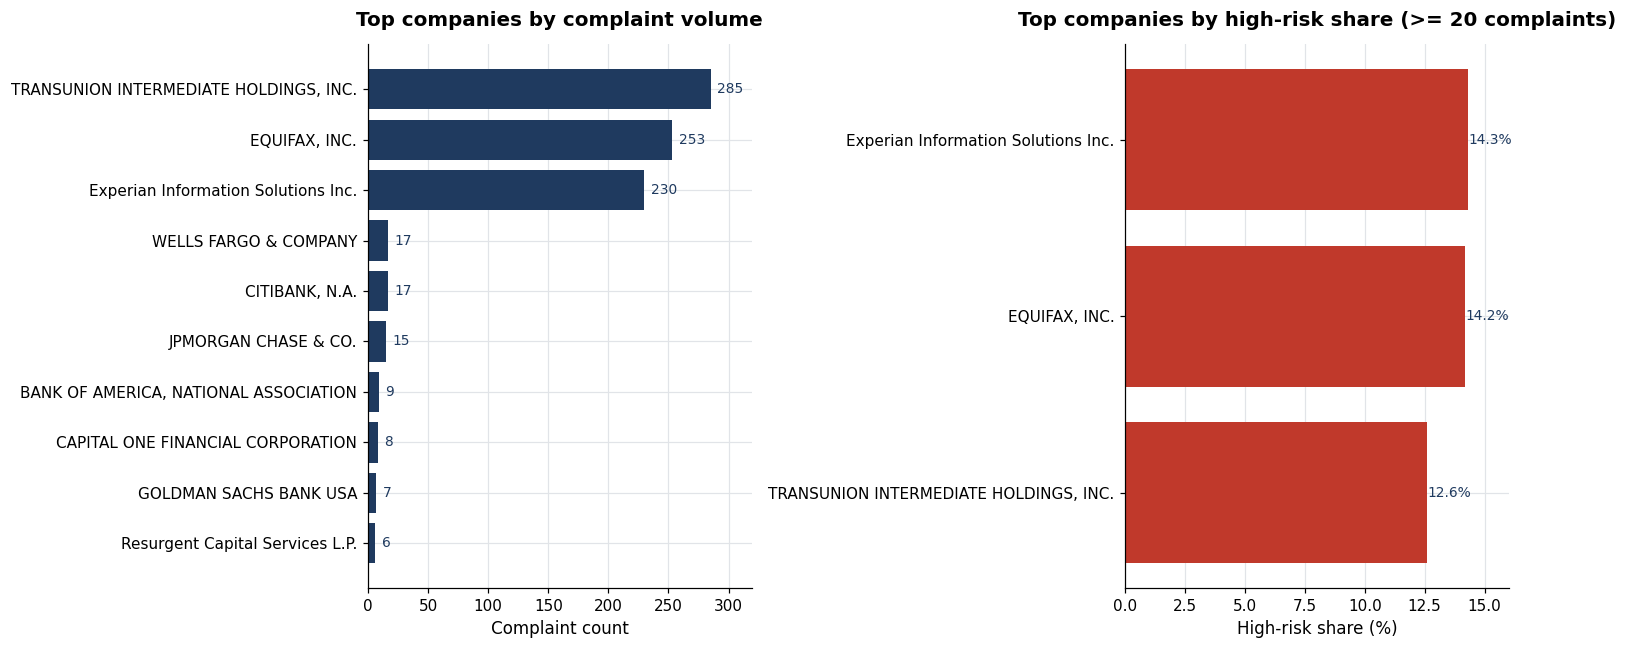

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top_volume = company_summary_full.head(10)
horizontal_bar(
    axes[0],
    top_volume["company"].astype(str).str.slice(0, 40),
    top_volume["complaints"],
    color=PALETTE["primary"],
)
axes[0].set_title("Top companies by complaint volume")
axes[0].set_xlabel("Complaint count")

top_risk = company_filtered.head(10)
horizontal_bar(
    axes[1],
    top_risk["company"].astype(str).str.slice(0, 40),
    top_risk["high_risk_share_pct"],
    color=PALETTE["warning"],
    value_format="{:.1f}%",
)
axes[1].set_title(f"Top companies by high-risk share (>= {min_volume} complaints)")
axes[1].set_xlabel("High-risk share (%)")
fig.tight_layout()
save_figure(ctx, fig, "company_volume_vs_risk")
plt.show()

## 4. Product mix inside top-volume companies

In [5]:
focus_companies = company_summary_full.head(5)["company"].tolist()
mix = (
    complaints.assign(
        company_clean=complaints["company"].fillna("Unknown").astype(str).str.strip(),
        product_clean=complaints["product"].fillna("Unknown").astype(str).str.strip(),
    )
    .query("company_clean in @focus_companies")
    .groupby(["company_clean", "product_clean"], as_index=False)
    .size()
    .rename(columns={"size": "complaints"})
)
mix_share = (
    mix.pivot_table(index="company_clean", columns="product_clean", values="complaints", fill_value=0)
)
mix_share = mix_share.div(mix_share.sum(axis=1), axis=0).round(3)
mix_share

product_clean,Checking or savings account,Credit card,Credit reporting or other personal consumer reports,Debt collection,Mortgage,Student loan
company_clean,,,,,,
"CITIBANK, N.A.",0.23,0.53,0.12,0.12,0.00,0.00
"EQUIFAX, INC.",0.00,0.00,0.97,0.03,0.00,0.00
Experian Information Solutions Inc.,0.00,0.00,0.96,0.04,0.00,0.00
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",0.00,0.00,0.94,0.06,0.00,0.00
WELLS FARGO & COMPANY,0.35,0.18,0.29,0.00,0.12,0.06


## 5. Insights

In [6]:
top_volume_row = company_summary_full.iloc[0]
if not company_filtered.empty:
    top_risk_row = company_filtered.iloc[0]
    risk_line = (
        f"- **Highest high-risk share (filtered)**: **{top_risk_row['company']}** "
        f"with {top_risk_row['high_risk_share_pct']:.1f}% on {int(top_risk_row['complaints'])} complaints."
    )
else:
    risk_line = (
        f"- After the >= {min_volume} complaints filter, no company has enough volume "
        "to support a stable high-risk-share ranking in this sample."
    )
narrative = "\n".join([
    f"- **Highest complaint volume**: **{top_volume_row['company']}** "
    f"({int(top_volume_row['complaints']):,} complaints, avg risk {top_volume_row['avg_risk_score']:.2f}).",
    risk_line,
    "- **Guardrails**: companies should be compared inside similar product mixes; "
    "credit-bureau-heavy firms will look different from monoline banks even at equal volume.",
])
display(Markdown(narrative))

- **Highest complaint volume**: **TRANSUNION INTERMEDIATE HOLDINGS, INC.** (285 complaints, avg risk 3.50).
- **Highest high-risk share (filtered)**: **Experian Information Solutions Inc.** with 14.3% on 230 complaints.
- **Guardrails**: companies should be compared inside similar product mixes; credit-bureau-heavy firms will look different from monoline banks even at equal volume.

## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/05/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [7]:
save_table(ctx, company_summary_full, "company_summary_full")
save_table(ctx, company_filtered.reset_index(drop=True), "company_summary_filtered")
mix_share.to_csv(ctx.artefact_dir / "company_product_mix_share.csv")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/05/company_product_mix_share.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/05/company_summary_filtered.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/05/company_summary_full.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/05/company_volume_vs_risk.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/05/environment.json')]